# LAB 10 — Fine-tuning DistilBERT cho Extractive QA (SQuAD v1.1)

Code lõi ở `qa_model.py`. Notebook này chạy:

1. dữ liệu, một batch đi qua model (`input_ids`, `attention_mask`, `offset_mapping`, `overflow_to_sample_mapping`, start / end logits);
2. baseline keyword overlap;
3. **Exp 1 + Exp 2** — fine-tune với max_length 128 / 256 / 384, learning curves;
4. **Exp 3** — EM vs F1, baseline vs Transformer; **Exp 4** — lexical overlap; **Exp 5** — độ dài đáp án;
5. thêm thông tin không liên quan / distractor / đổi thứ tự câu (Prediction 3, 4);
6. error analysis: wrong start / wrong end / wrong span.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import time, gc, random, re
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import transformers; transformers.logging.set_verbosity_error()
from transformers import AutoTokenizer, AutoModelForQuestionAnswering
import qa_model as qm
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
print("torch", torch.__version__, "| transformers", transformers.__version__, "|", qm.DEVICE,
      torch.cuda.get_device_name() if torch.cuda.is_available() else "")
if os.environ.get("LAB10_LOG"):                      # ghi thêm mọi dòng print ra file để theo dõi tiến độ
    import builtins
    _print = builtins.print
    def _tee(*a, **k):
        _print(*a, **k)
        with open(os.environ["LAB10_LOG"], "a", encoding="utf-8") as f:
            f.write(time.strftime("%H:%M:%S ") + " ".join(map(str, a)) + "\n")
    builtins.print = _tee
RESULTS = []
def log(exp, setting, metric, value):
    RESULTS.append({"experiment": exp, "setting": setting, "metric": metric, "value": float(value)})

torch 2.6.0+cu124 | transformers 5.17.0 | cuda NVIDIA GeForce RTX 3050 Laptop GPU


## 1. Dữ liệu

- **train:** 30 000 câu hỏi lấy ngẫu nhiên (seed 42) từ SQuAD train, sau khi bỏ 25 bài Wikipedia;
- **validation:** 2 000 câu hỏi từ 25 bài giữ riêng, nên context không trùng với train;
- **test:** SQuAD v1.1 dev chính thức, 10 570 câu hỏi từ 48 bài, mỗi câu có tới 3 đáp án gold.

Chỉ dùng 30 000 / 87 599 câu hỏi train vì giới hạn thời gian trên GPU laptop (ba lần fine-tune cho Exp 1).

In [2]:
data = qm.load_squad()
QUICK = os.environ.get("LAB10_QUICK") == "1"         # chạy thử nhanh trên dữ liệu nhỏ
if QUICK:
    data = {k: v[:n] for (k, v), n in zip(data.items(), [800, 200, 600])}
EPOCHS, CKPT = (1, "ckpt_quick") if QUICK else (2, "ckpt")
for k, v in data.items():
    alen = [len(e["answers"]["text"][0].split()) for e in v]
    print(f"{k:10}: {len(v)} câu hỏi, {len({e['context'] for e in v})} context, {len({e['title'] for e in v})} bài | "
          f"context median {np.median([len(e['context'].split()) for e in v]):.0f} word | đáp án median {np.median(alen):.0f} word")
tok = AutoTokenizer.from_pretrained(qm.MODEL_NAME)
print(type(tok).__name__, "| model_input_names:", tok.model_input_names)

train     : 30000 câu hỏi, 15029 context, 417 bài | context median 110 word | đáp án median 2 word
validation: 2000 câu hỏi, 988 context, 25 bài | context median 109 word | đáp án median 2 word
test      : 10570 câu hỏi, 2067 context, 48 bài | context median 112 word | đáp án median 2 word


BertTokenizer | model_input_names: ['input_ids', 'token_type_ids', 'attention_mask']


## 2. Tokenize question + context, offset mapping, sliding window (stride 128)

In [3]:
ex = max(data["test"], key=lambda e: len(e["context"]))
enc = qm.encode_windows(tok, [ex], 384, 128)          # sliding window tự cắt (xem tokenizer_alignment.ipynb, mục 5)
print("keys:", list(enc.keys()))
print(f"question: {ex['question']!r} | context {len(ex['context'])} ký tự | gold: {ex['answers']['text'][0]!r} @ {ex['answers']['answer_start'][0]}")
print("số window:", len(enc["input_ids"]), "| overflow_to_sample_mapping:", enc["overflow_to_sample_mapping"])
a_s = ex["answers"]["answer_start"][0]; a_e = a_s + len(ex["answers"]["text"][0])
for k in range(len(enc["input_ids"])):
    seq = enc["sequence_ids"][k]; ctx = [i for i, s in enumerate(seq) if s == 1]
    s, e = qm.char_to_token_span(enc["offset_mapping"][k], seq, a_s, a_e)
    print(f"  window {k}: {len(enc['input_ids'][k])} token, context ký tự [{enc['offset_mapping'][k][ctx[0]][0]}, {enc['offset_mapping'][k][ctx[-1]][1]}) "
          f"→ start/end token = ({s}, {e}) {tok.convert_ids_to_tokens(enc['input_ids'][k][s:e + 1]) if s else '(không chứa đáp án → [CLS])'}")
k0 = 0
print()
print("20 token đầu window 0 (attention_mask = 1 ở mọi token thật; padding thêm khi tạo batch có mask 0):")
print(pd.DataFrame({"token": tok.convert_ids_to_tokens(enc["input_ids"][k0])[:20], "input_id": enc["input_ids"][k0][:20],
                    "sequence_id": enc["sequence_ids"][k0][:20], "offset": enc["offset_mapping"][k0][:20]}).T.to_string())

keys: ['input_ids', 'offset_mapping', 'sequence_ids', 'overflow_to_sample_mapping']
question: 'The freedom to provide services under TFEU article 56 applies to who?' | context 4063 ký tự | gold: 'to people who give services "for remuneration"' @ 64
số window: 3 | overflow_to_sample_mapping: [0, 0, 0]
  window 0: 384 token, context ký tự [0, 1862) → start/end token = (31, 41) ['to', 'people', 'who', 'give', 'services', '"', 'for', 're', '##mun', '##eration', '"']
  window 1: 384 token, context ký tự [1149, 3143) → start/end token = (0, 0) (không chứa đáp án → [CLS])
  window 2: 331 token, context ký tự [2442, 4063) → start/end token = (0, 0) (không chứa đáp án → [CLS])

20 token đầu window 0 (attention_mask = 1 ở mọi token thật; padding thêm khi tạo batch có mask 0):
                 0       1        2         3         4         5         6         7         8         9         10        11        12        13        14        15      16      17      18       19
token         [CLS]    

In [4]:
model = AutoModelForQuestionAnswering.from_pretrained(qm.MODEL_NAME)
print("QA head:", model.qa_outputs, "→ 2 logit / token (start, end):", sum(p.numel() for p in model.qa_outputs.parameters()), "tham số")
feats = qm.prepare_train_features(tok, data["train"][:8], 384, 128)
b, x, m, ys, ye = next(qm.batches(feats, 8))
with torch.no_grad():
    out = model(input_ids=x, attention_mask=m, output_hidden_states=True)
for name, t in [("input_ids", x), ("attention_mask", m), ("hidden states H", out.hidden_states[-1]),
                ("start_logits", out.start_logits), ("end_logits", out.end_logits), ("start labels", ys), ("end labels", ye)]:
    print(f"{name:16} {tuple(t.shape)}")
print("loss chưa train = (L_start + L_end) / 2 =", round(qm.qa_loss(out.start_logits, out.end_logits, ys, ye).item(), 4),
      f"(≈ ln T = {np.log(x.shape[1]):.2f} vì softmax gần đều)")
del model

QA head: Linear(in_features=768, out_features=2, bias=True) → 2 logit / token (start, end): 1538 tham số


input_ids        (8, 270)
attention_mask   (8, 270)
hidden states H  (8, 270, 768)
start_logits     (8, 270)
end_logits       (8, 270)
start labels     (8,)
end labels       (8,)
loss chưa train = (L_start + L_end) / 2 = 5.6047 (≈ ln T = 5.60 vì softmax gần đều)


## 3. Baseline — keyword overlap → câu ứng viên → span ứng viên

In [5]:
def run_baseline(examples):
    return {e["id"]: dict(zip(["text", "char_start", "char_end"], qm.baseline_answer(e["question"], e["context"]))) for e in examples}
BASE = {sp: run_baseline(data[sp]) for sp in ["validation", "test"]}
for sp in ["validation", "test"]:
    r = qm.evaluate(BASE[sp], data[sp]); print(f"baseline {sp}: EM {r['em']:.2f} | F1 {r['f1']:.2f}")
    log("baseline", sp, "em", r["em"]); log("baseline", sp, "f1", r["f1"])
# câu chứa đáp án gold có phải câu baseline chọn không?
def sentence_of(ctx, c):
    return next(i for i, (s, t) in enumerate(qm._sentences(ctx)) if c <= t)
hit = np.mean([sentence_of(e["context"], BASE["test"][e["id"]]["char_start"]) == sentence_of(e["context"], e["answers"]["answer_start"][0])
               for e in data["test"]])
print(f"baseline chọn đúng câu chứa đáp án: {hit:.1%}")
log("baseline", "test", "correct sentence", hit)

baseline validation: EM 13.45 | F1 26.87


baseline test: EM 15.42 | F1 28.27


baseline chọn đúng câu chứa đáp án: 77.9%


## 4. Exp 1 + Exp 2 — Fine-tuning với max_length 128 / 256 / 384

DistilBERT (`distilbert-base-uncased`), AdamW lr 3e-5, weight decay 0.01, warmup 10% rồi giảm tuyến tính, batch 16, 2 epoch, bf16, clip 1.0. stride = 64 / 128 / 128 (token chồng lấn giữa hai window liên tiếp; với T = 128 phải nhỏ hơn vì phần context của window chỉ khoảng 100 token). Ghi train / validation loss 4 lần mỗi epoch; chọn epoch có validation F1 cao nhất. Mọi thứ khác giữ nguyên.

In [6]:
CFG = {128: 64, 256: 128, 384: 128}
os.makedirs(CKPT, exist_ok=True)
runs, models = {}, {}
for T, stride in CFG.items():
    print(f"=== max_length {T}, stride {stride}")
    tr = qm.prepare_train_features(tok, data["train"], T, stride)
    va = qm.prepare_eval_features(tok, data["validation"], T, stride)
    te = qm.prepare_eval_features(tok, data["test"], T, stride)
    qm.set_seed()
    model = AutoModelForQuestionAnswering.from_pretrained(qm.MODEL_NAME)
    info = qm.train_qa(model, tr, va, data["validation"], epochs=EPOCHS, ckpt=f"{CKPT}/T{T}", log=print)
    t0 = time.time()
    S, E, test_loss = qm.predict_logits(model, te)
    preds = qm.postprocess(data["test"], te, S, E)
    r = qm.evaluate(preds, data["test"])
    runs[T] = {**info, **r, "test_loss": test_loss, "test_time": time.time() - t0, "preds": preds,
               "n_test_features": len(te), "no_answer_windows": np.mean([f["start"] == 0 for f in tr])}
    print(f"  → test EM {r['em']:.2f} | F1 {r['f1']:.2f} | train {info['train_time']:.0f}s | best epoch {info['best_epoch']} | skipped {info['skipped']}")
    for k in ["em", "f1", "train_time", "test_loss", "best_epoch", "skipped", "n_train_features", "no_answer_windows"]:
        log("Exp1", f"T={T}", k, runs[T][k])
    for c in info["curve"]:
        log("Exp2 curve", f"T={T} epoch={c['epoch']:.2f}", "train_loss", c["train_loss"]); log("Exp2 curve", f"T={T} epoch={c['epoch']:.2f}", "val_loss", c["val_loss"])
    if T == 384:
        models[T], TE384 = model.cpu(), te
    else:
        del model
    gc.collect(); torch.cuda.empty_cache()
exp1 = pd.DataFrame([{"max length": T, "stride": CFG[T], "train features": r["n_train_features"], "% window không chứa đáp án": r["no_answer_windows"],
                      "test features": r["n_test_features"], "EM": r["em"], "F1": r["f1"], "train time (s)": r["train_time"],
                      "best epoch": r["best_epoch"], "val EM / F1 (best)": f"{r['epochs'][r['best_epoch'] - 1]['em']:.2f} / {r['epochs'][r['best_epoch'] - 1]['f1']:.2f}"}
                     for T, r in runs.items()]).set_index("max length")
exp1.round(3)

=== max_length 128, stride 64


  epoch 0.25: train loss 2.3553 | val loss 1.3647


  epoch 0.50: train loss 1.3387 | val loss 1.0721


  epoch 0.75: train loss 1.1419 | val loss 1.0163


  epoch 1.00: train loss 1.0435 | val loss 0.9117


  epoch 1: val EM 62.65 | val F1 74.83


... (27 outputs left out)

  epoch 2.00: train loss 1.0623 | val loss 1.1654


  epoch 2: val EM 62.40 | val F1 75.48


  → test EM 71.07 | F1 80.49 | train 950s | best epoch 2 | skipped 7


,stride,train features,% window không chứa đáp án,test features,EM,F1,train time (s),best epoch,val EM / F1 (best)
max length,,,,,,,,,
128,64,72988,0.427,27090,70.464,79.417,1131.641,2,63.85 / 75.70
256,128,33362,0.070,12097,70.766,80.173,842.843,2,62.25 / 75.58
384,128,30319,0.009,10784,71.069,80.492,950.136,2,62.40 / 75.48


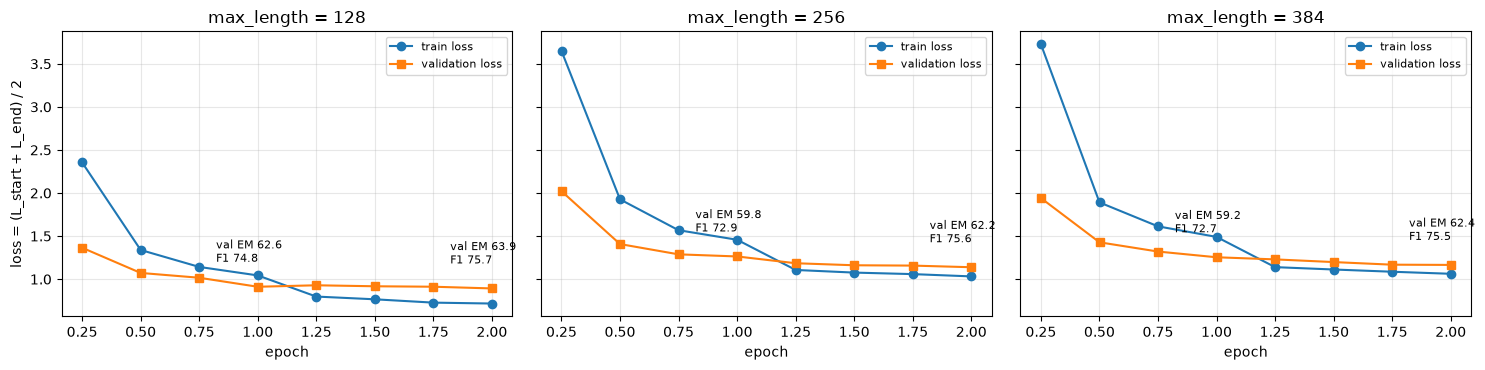

,T,epoch,train_loss,val_loss
0,128,0.2499,2.3553,1.3647
1,128,0.5000,1.3387,1.0721
2,128,0.7501,1.1419,1.0163
3,128,1.0000,1.0435,0.9117
4,128,1.2499,0.7980,0.9289
5,128,1.5000,0.7661,0.9174
6,128,1.7501,0.7275,0.9121
7,128,2.0000,0.7170,0.8923
8,256,0.2502,3.6488,2.0211
9,256,0.5000,1.9264,1.4074


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, (T, r) in zip(ax, runs.items()):
    c = pd.DataFrame(r["curve"])
    a.plot(c.epoch, c.train_loss, "-o", label="train loss"); a.plot(c.epoch, c.val_loss, "-s", label="validation loss")
    for h in r["epochs"]:
        a.annotate(f"val EM {h['em']:.1f}\nF1 {h['f1']:.1f}", (h["epoch"], c[c.epoch.round(2) == h["epoch"]].val_loss.iloc[0]),
                   textcoords="offset points", xytext=(-30, 18), fontsize=8)
    a.set(title=f"max_length = {T}", xlabel="epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[0].set_ylabel("loss = (L_start + L_end) / 2")
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=120); plt.show()
pd.DataFrame([{"T": T, **c} for T, r in runs.items() for c in r["curve"]]).round(4)

## 5. Exp 3 — EM vs F1, baseline vs Transformer (test)

In [8]:
P = runs[384]["preds"]
rows = []
for e in data["test"]:
    em_m, f1_m = qm.score_one(P[e["id"]]["text"], e["answers"]["text"])
    em_b, f1_b = qm.score_one(BASE["test"][e["id"]]["text"], e["answers"]["text"])
    rows.append({"id": e["id"], "question": e["question"], "gold": e["answers"]["text"], "pred": P[e["id"]]["text"],
                 "base": BASE["test"][e["id"]]["text"], "em": em_m, "f1": f1_m, "em_b": em_b, "f1_b": f1_b})
D = pd.DataFrame(rows)
tab3 = pd.DataFrame({"EM": [D.em_b.mean() * 100, D.em.mean() * 100], "F1": [D.f1_b.mean() * 100, D.f1.mean() * 100],
                     "% EM = 0 nhưng F1 > 0": [((D.em_b == 0) & (D.f1_b > 0)).mean() * 100, ((D.em == 0) & (D.f1 > 0)).mean() * 100],
                     "% F1 = 0": [(D.f1_b == 0).mean() * 100, (D.f1 == 0).mean() * 100]},
                    index=["Baseline (keyword overlap)", "DistilBERT fine-tuned (T = 384)"])
for m, r in tab3.iterrows():
    for c in tab3.columns: log("Exp3", m, c, r[c])
tab3.round(2)

,EM,F1,% EM = 0 nhưng F1 > 0,% F1 = 0
Baseline (keyword overlap),15.42,28.27,24.12,60.46
DistilBERT fine-tuned (T = 384),71.07,80.49,17.38,11.55


1837 câu hỏi EM = 0 nhưng F1 > 0. 8 ví dụ (ngẫu nhiên, seed 0):
  Q: What could justify restrictions on freedom of establishment?
     gold: 'creditor protection, labour rights to participate in work, or the public interest in collecting taxes' | pred: 'creditor protection' | overlap 2, P = 2/2, R = 2/14 → F1 0.250
  Q: As a norm, what day of the week is the traditional Media Day held prior to a Super Bowl?
     gold: 'Tuesday' | pred: 'Tuesday afternoon' | overlap 1, P = 1/2, R = 1/1 → F1 0.667
  Q: How can someone be recognized as local church lay servant?
     gold: 'recommended by their pastor and Church Council or Charge Conference, and complete the basic course for lay servant' | pred: 'their pastor and Church Council or Charge Conference' | overlap 8, P = 8/8, R = 8/17 → F1 0.640
  Q: How did Luther respond to Agricola?
     gold: 'six series of theses against Agricola' | pred: 'six series of theses against Agricola and the antinomians' | overlap 6, P = 6/8, R = 6/6 → F1 0.857
 

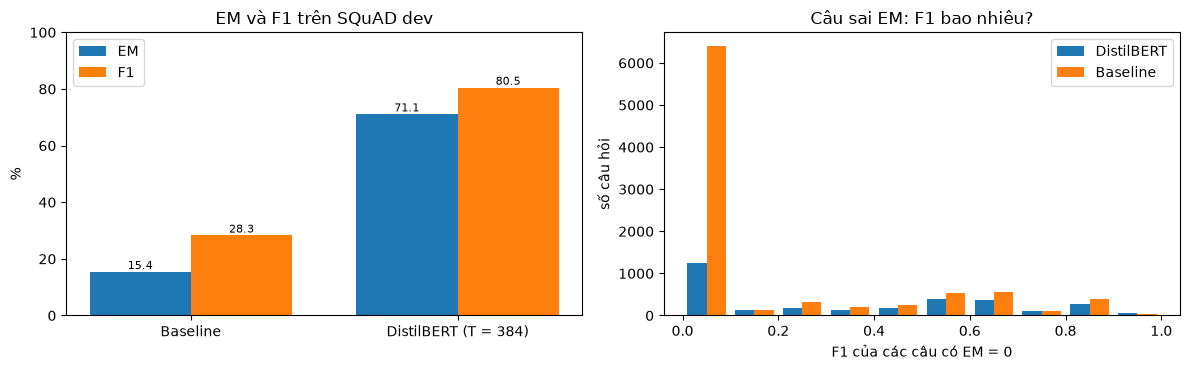

In [9]:
part = D[(D.em == 0) & (D.f1 > 0)]
print(f"{len(part)} câu hỏi EM = 0 nhưng F1 > 0. 8 ví dụ (ngẫu nhiên, seed 0):")
for _, r in part.sample(min(8, len(part)), random_state=0).iterrows():
    g = max(r.gold, key=lambda x: qm.f1(r.pred, x))
    pn, gn = qm.normalize_answer(r.pred).split(), qm.normalize_answer(g).split()
    ov = sum((Counter(pn) & Counter(gn)).values())
    print(f"  Q: {r.question}\n     gold: {g!r} | pred: {r.pred!r} | overlap {ov}, P = {ov}/{len(pn)}, R = {ov}/{len(gn)} → F1 {r.f1:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.38; xs = np.arange(2)
ax[0].bar(xs - w / 2, tab3.EM, w, label="EM"); ax[0].bar(xs + w / 2, tab3.F1, w, label="F1")
for i, (a, b) in enumerate(zip(tab3.EM, tab3.F1)):
    ax[0].text(i - w / 2, a + 1, f"{a:.1f}", ha="center", fontsize=8); ax[0].text(i + w / 2, b + 1, f"{b:.1f}", ha="center", fontsize=8)
ax[0].set(xticks=xs, xticklabels=["Baseline", "DistilBERT (T = 384)"], ylabel="%", ylim=(0, 100), title="EM và F1 trên SQuAD dev"); ax[0].legend()
ax[1].hist([D[D.em == 0].f1, D[D.em_b == 0].f1_b], bins=np.linspace(0, 1, 11), label=["DistilBERT", "Baseline"])
ax[1].set(xlabel="F1 của các câu có EM = 0", ylabel="số câu hỏi", title="Câu sai EM: F1 bao nhiêu?"); ax[1].legend()
plt.tight_layout(); plt.savefig("em_f1_analysis.png", dpi=120); plt.show()

## 6. Exp 4 — Question / context matching (lexical overlap)

overlap = tỉ lệ từ nội dung của câu hỏi (bỏ stopword) xuất hiện trong **câu chứa đáp án**. Chia 3 nhóm: thấp (< 0.4), trung bình (0.4–0.7), cao (≥ 0.7).

In [10]:
def content(s):
    return {w.lower() for w in qm._TOK.findall(s) if w.isalnum() and w.lower() not in qm.STOP}
def answer_sentence(e):
    a = e["answers"]["answer_start"][0]
    for s, t in qm._sentences(e["context"]):
        if s <= a < t: return e["context"][s:t]
    return e["context"]
D["overlap"] = [len(content(e["question"]) & content(answer_sentence(e))) / max(1, len(content(e["question"]))) for e in data["test"]]
D["overlap group"] = pd.cut(D.overlap, [-0.01, 0.4, 0.7, 1.01], labels=["thấp (< 0.4)", "trung bình", "cao (≥ 0.7)"])
tab4 = D.groupby("overlap group", observed=True).agg(n=("em", "size"), base_EM=("em_b", "mean"), base_F1=("f1_b", "mean"),
                                                      bert_EM=("em", "mean"), bert_F1=("f1", "mean"))
tab4[["base_EM", "base_F1", "bert_EM", "bert_F1"]] *= 100
for g, r in tab4.iterrows():
    for c in tab4.columns: log("Exp4", str(g), c, r[c])
tab4.round(2)

,n,base_EM,base_F1,bert_EM,bert_F1
overlap group,,,,,
thấp (< 0.4),3172,6.81,15.33,62.83,72.46
trung bình,3911,15.90,29.64,72.03,81.46
cao (≥ 0.7),3487,22.71,38.50,77.49,86.71


Thêm một tập nhỏ tự viết: cùng một sự kiện, một câu hỏi dùng đúng từ của context, một câu hỏi diễn đạt lại.

In [11]:
PARA = [
    ("Paris is the capital of France.", "Paris", "What city is the capital of France?", "Where is the French government based?"),
    ("The Eiffel Tower was completed in 1889 for the World's Fair.", "1889", "When was the Eiffel Tower completed?", "In what year did construction of the famous Paris landmark finish?"),
    ("Marie Curie won the Nobel Prize in Chemistry in 1911.", "Marie Curie", "Who won the Nobel Prize in Chemistry in 1911?", "Which scientist received chemistry's top award in 1911?"),
    ("The Amazon River flows through Brazil, Peru and Colombia.", "Brazil, Peru and Colombia", "Which countries does the Amazon River flow through?", "Through which nations does South America's largest river pass?"),
    ("Hanoi has a population of about 8 million people.", "about 8 million", "What is the population of Hanoi?", "How many people live in the Vietnamese capital?"),
    ("The company was founded by Steve Jobs and Steve Wozniak in a garage.", "Steve Jobs and Steve Wozniak", "Who founded the company?", "Who started the business?"),
    ("Water boils at 100 degrees Celsius at sea level.", "100 degrees Celsius", "At what temperature does water boil at sea level?", "How hot must water get before it turns to steam near the ocean?"),
    ("The treaty was signed in Versailles after the end of the First World War.", "Versailles", "Where was the treaty signed?", "In which location did the parties put their names on the agreement?"),
]
para_ex = [{"id": f"p{i}{k}", "question": q, "context": c, "answers": {"text": [a], "answer_start": [c.index(a)]}}
           for i, (c, a, q1, q2) in enumerate(PARA) for k, q in [("same", q1), ("para", q2)]]
mdl = models[384].to(qm.DEVICE)
pf = qm.prepare_eval_features(tok, para_ex, 384, 128)
S, E, _ = qm.predict_logits(mdl, pf); pp = qm.postprocess(para_ex, pf, S, E)
pb = run_baseline(para_ex)
pt = pd.DataFrame([{"kiểu": e["id"][2:], "question": e["question"], "gold": e["answers"]["text"][0], "DistilBERT": pp[e["id"]]["text"],
                    "baseline": pb[e["id"]]["text"]} for e in para_ex])
print(pt.groupby("kiểu").apply(lambda g: pd.Series({"DistilBERT EM": np.mean([qm.exact_match(a, b) for a, b in zip(g.DistilBERT, g.gold)]),
                                                     "baseline EM": np.mean([qm.exact_match(a, b) for a, b in zip(g.baseline, g.gold)])})))
pt

      DistilBERT EM  baseline EM
kiểu                            
para          0.875         0.25
same          0.875         0.50


,kiểu,question,gold,DistilBERT,baseline
0,same,What city is the capital of France?,Paris,Paris,Paris
1,para,Where is the French government based?,Paris,Paris,Paris
2,same,When was the Eiffel Tower completed?,1889,1889,1889
3,para,In what year did construction of the famous Paris landmark finish?,1889,1889,1889
4,same,Who won the Nobel Prize in Chemistry in 1911?,Marie Curie,Marie Curie,Marie Curie
5,para,Which scientist received chemistry's top award in 1911?,Marie Curie,Marie Curie,Chemistry
6,same,Which countries does the Amazon River flow through?,"Brazil, Peru and Colombia","Brazil, Peru and Colombia",Brazil
7,para,Through which nations does South America's largest river pass?,"Brazil, Peru and Colombia","Brazil, Peru and Colombia",Amazon
8,same,What is the population of Hanoi?,about 8 million,8 million,about 8 million people
9,para,How many people live in the Vietnamese capital?,about 8 million,8 million,Hanoi has a population of about


## 7. Exp 5 — Độ dài đáp án (số word của đáp án gold đầu tiên)

                 n  base_EM  base_F1  bert_EM  bert_F1
length group                                          
1             3429    20.21    29.86    75.79    81.80
2–3           4575    15.89    29.83    74.56    82.60
4–6           1648    10.56    25.42    67.11    80.09
7+             918     3.92    19.68    43.14    65.81

Độ dài trung bình đáp án dự đoán / gold theo nhóm:
              pred_len  ans_len
length group                   
1                 1.98     1.00
2–3               3.02     2.37
4–6               4.59     4.67
7+                6.70    10.80


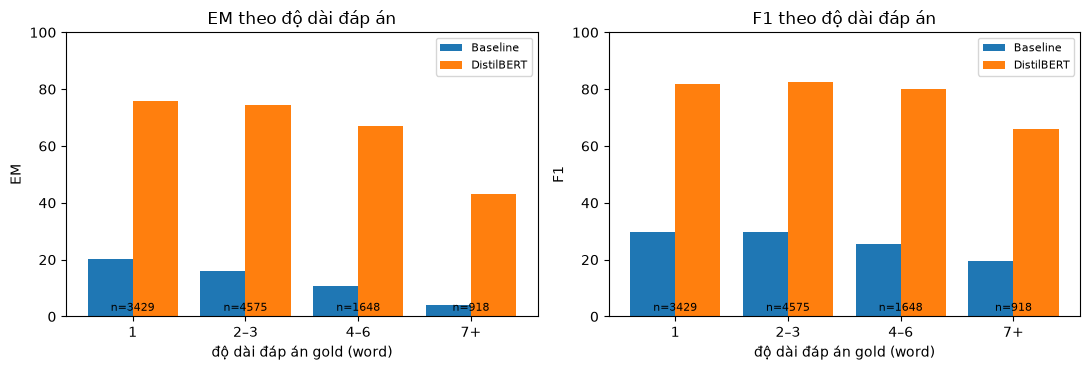

In [12]:
D["ans_len"] = [len(e["answers"]["text"][0].split()) for e in data["test"]]
D["length group"] = pd.cut(D.ans_len, [0, 1, 3, 6, 1000], labels=["1", "2–3", "4–6", "7+"])
tab5 = D.groupby("length group", observed=True).agg(n=("em", "size"), base_EM=("em_b", "mean"), base_F1=("f1_b", "mean"),
                                                     bert_EM=("em", "mean"), bert_F1=("f1", "mean"))
tab5[["base_EM", "base_F1", "bert_EM", "bert_F1"]] *= 100
for g, r in tab5.iterrows():
    for c in tab5.columns: log("Exp5", str(g), c, r[c])
print(tab5.round(2))
D["pred_len"] = [len(t.split()) for t in D.pred]
print("\nĐộ dài trung bình đáp án dự đoán / gold theo nhóm:")
print(D.groupby("length group", observed=True)[["pred_len", "ans_len"]].mean().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
xs = np.arange(len(tab5))
for a, met in zip(ax, ["EM", "F1"]):
    a.bar(xs - 0.2, tab5[f"base_{met}"], 0.4, label="Baseline"); a.bar(xs + 0.2, tab5[f"bert_{met}"], 0.4, label="DistilBERT")
    for i, n in enumerate(tab5.n): a.text(i, 2, f"n={n}", ha="center", fontsize=8)
    a.set(xticks=xs, xticklabels=tab5.index, xlabel="độ dài đáp án gold (word)", ylabel=met, ylim=(0, 100), title=f"{met} theo độ dài đáp án"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("answer_length_analysis.png", dpi=120); plt.show()

## 8. Context không liên quan, distractor, đổi thứ tự câu (Prediction 3, 4)

Lấy 1 000 câu hỏi test (seed 42) có đáp án nằm gọn trong một câu. Với mỗi câu hỏi tạo 4 phiên bản context, đáp án giữ nguyên:

- **gốc**;
- **+ không liên quan:** chèn 3 câu lấy ngẫu nhiên từ bài khác vào các vị trí ngẫu nhiên giữa các câu;
- **+ distractor:** chèn 1 câu tạo từ chính câu hỏi, thay từ hỏi bằng một đáp án giả cùng loại câu hỏi (lấy từ câu hỏi khác). Ví dụ "Who founded SpaceX?" → "Tim Cook founded SpaceX.";
- **đổi thứ tự:** xáo trộn thứ tự các câu.

In [13]:
rng = random.Random(42)
WH = ["how many", "how much", "what year", "who", "when", "where", "which", "what", "how"]
def wh_of(q):
    ql = q.lower()
    return next((w for w in WH if re.search(r"\b" + w + r"\b", ql)), None)
pool = {}
for e in data["test"]:
    w = wh_of(e["question"])
    if w: pool.setdefault(w, []).append(e["answers"]["text"][0])
other_sents = [e["context"][s:t] for e in data["validation"] for s, t in qm._sentences(e["context"]) if 40 < t - s < 200]

def split_with_answer(e):
    sents = qm._sentences(e["context"]); a, b = e["answers"]["answer_start"][0], e["answers"]["answer_start"][0] + len(e["answers"]["text"][0])
    k = [i for i, (s, t) in enumerate(sents) if s <= a and b <= t]
    return ([e["context"][s:t] for s, t in sents], k[0]) if k else (None, None)

def rebuild(e, sents, ans_idx, tag):
    ctx, pos = "", None
    for i, s in enumerate(sents):
        if i: ctx += " "
        if i == ans_idx: pos = len(ctx) + s.index(e["answers"]["text"][0])
        ctx += s
    golds = [g for g in e["answers"]["text"] if g in sents[ans_idx]] or [e["answers"]["text"][0]]
    return {"id": e["id"] + tag, "question": e["question"], "context": ctx, "answers": {"text": golds, "answer_start": [pos] * len(golds)}}

def distractor(q, fake):
    w = wh_of(q); body = re.sub(r"\?\s*$", "", q.strip())
    body = re.sub(r"(?i)\b" + w + r"\b", fake, body, count=1)
    return body[0].upper() + body[1:] + "."

sets = {"gốc": [], "+ không liên quan": [], "+ distractor": [], "đổi thứ tự": []}
fakes = {}
cand = [e for e in data["test"] if split_with_answer(e)[0] and len(split_with_answer(e)[0]) >= 2 and wh_of(e["question"])]
for e in rng.sample(cand, min(1000, len(cand))):
    sents, ai = split_with_answer(e)
    sets["gốc"].append(rebuild(e, sents, ai, ""))
    s2, a2 = list(sents), ai
    for x in rng.sample(other_sents, 3):
        p = rng.randint(0, len(s2)); s2.insert(p, x); a2 += p <= a2
    sets["+ không liên quan"].append(rebuild(e, s2, a2, "_irr"))
    golds_n = {qm.normalize_answer(g) for g in e["answers"]["text"]}
    fake = next(f for f in rng.sample(pool[wh_of(e["question"])], min(50, len(pool[wh_of(e["question"])]))) if qm.normalize_answer(f) not in golds_n and f not in e["context"])
    fakes[e["id"]] = fake
    s3, a3 = list(sents), ai
    p = rng.randint(0, len(s3)); s3.insert(p, distractor(e["question"], fake)); a3 += p <= a3
    sets["+ distractor"].append(rebuild(e, s3, a3, "_dis"))
    order = list(range(len(sents))); rng.shuffle(order)
    sets["đổi thứ tự"].append(rebuild(e, [sents[i] for i in order], order.index(ai), "_shuf"))
print("Ví dụ distractor:", sets["+ distractor"][0]["question"], "→", distractor(sets["gốc"][0]["question"], fakes[sets["gốc"][0]["id"]]))

rows, PERT = [], {}
for name, exs in sets.items():
    f_ = qm.prepare_eval_features(tok, exs, 384, 128)
    S, E, _ = qm.predict_logits(mdl, f_); pr = qm.postprocess(exs, f_, S, E); PERT[name] = pr
    r_m, r_b = qm.evaluate(pr, exs), qm.evaluate(run_baseline(exs), exs)
    row = {"context": name, "window / câu hỏi": len(f_) / len(exs), "DistilBERT EM": r_m["em"], "DistilBERT F1": r_m["f1"],
           "baseline EM": r_b["em"], "baseline F1": r_b["f1"]}
    if name == "+ distractor":
        row["% chọn đáp án giả"] = 100 * np.mean([qm.normalize_answer(fakes[e["id"][:-4]]) in qm.normalize_answer(pr[e["id"]]["text"]) for e in exs])
        bp = run_baseline(exs)
        row["% baseline chọn đáp án giả"] = 100 * np.mean([qm.normalize_answer(fakes[e["id"][:-4]]) in qm.normalize_answer(bp[e["id"]]["text"]) for e in exs])
    rows.append(row)
    for k, v in row.items():
        if k != "context": log("Perturbation", name, k, v)
pert = pd.DataFrame(rows).set_index("context")
base_pr = PERT["gốc"]
for name in ["+ không liên quan", "+ distractor", "đổi thứ tự"]:
    same = np.mean([qm.normalize_answer(base_pr[e["id"]]["text"]) == qm.normalize_answer(PERT[name][e["id"] + {"+ không liên quan": "_irr", "+ distractor": "_dis", "đổi thứ tự": "_shuf"}[name]]["text"])
                    for e in sets["gốc"]])
    pert.loc[name, "% dự đoán giữ nguyên"] = 100 * same
pert.round(2)

Ví dụ distractor: What country's schools have codes of behavior that are very strict? → Republic of Kenya country's schools have codes of behavior that are very strict.


,window / câu hỏi,DistilBERT EM,DistilBERT F1,baseline EM,baseline F1,% chọn đáp án giả,% baseline chọn đáp án giả,% dự đoán giữ nguyên
context,,,,,,,,
gốc,1.02,73.1,80.60,15.1,27.79,NaN,NaN,NaN
+ không liên quan,1.05,71.1,79.11,15.0,27.56,NaN,NaN,83.9
+ distractor,1.02,18.7,22.40,2.7,4.29,70.5,69.1,20.6
đổi thứ tự,1.02,71.2,79.09,15.0,28.13,NaN,NaN,84.4


In [14]:
print("Ví dụ model bị distractor lừa (trả lời đúng ở context gốc, sai sau khi thêm distractor):")
shown = 0
for e in sets["+ distractor"]:
    fake, pred = fakes[e["id"][:-4]], PERT["+ distractor"][e["id"]]["text"]
    if qm.normalize_answer(fake) in qm.normalize_answer(pred) and qm.exact_match(base_pr[e["id"][:-4]]["text"], e["answers"]["text"][0]):
        print(f"  Q: {e['question']} | gold: {e['answers']['text'][0]!r} | pred: {pred!r}\n     distractor: {distractor(e['question'], fake)}")
        shown += 1
    if shown == 6:
        break

Ví dụ model bị distractor lừa (trả lời đúng ở context gốc, sai sau khi thêm distractor):
  Q: What country's schools have codes of behavior that are very strict? | gold: 'Japan' | pred: 'Republic of Kenya'
     distractor: Republic of Kenya country's schools have codes of behavior that are very strict.
  Q: Who appointed Samuel Phillips to man the tiger team to find answers? | gold: 'George Mueller' | pred: 'Henry Cavendish'
     distractor: Henry Cavendish appointed Samuel Phillips to man the tiger team to find answers.
  Q: To what level would the polynomial time hierarchy collapse if graph isomorphism is NP-complete? | gold: 'second level' | pred: 'extreme change level'
     distractor: To extreme change level would the polynomial time hierarchy collapse if graph isomorphism is NP-complete.
  Q: Who was the ESPN Deportes sideline commentator for Super Bowl 50? | gold: 'John Sutcliffe.' | pred: 'Anglo-Saxon populations'
     distractor: Anglo-Saxon populations was the ESPN Deportes s

## 9. Error analysis — wrong start / wrong end / wrong span (DistilBERT T = 384, test)

So span dự đoán với span gold gần nhất (gold có F1 cao nhất), theo vị trí ký tự trong context. Start (hoặc end) được tính là **đúng** nếu phần chênh giữa hai vị trí chỉ gồm khoảng trắng, dấu câu hoặc mạo từ (bị bỏ khi chuẩn hóa).

- **correct:** đúng cả hai (EM = 1);
- **wrong end:** start đúng, end sai;
- **wrong start:** end đúng, start sai;
- **wrong boundary:** sai cả hai nhưng có chồng lấn;
- **wrong span:** không chồng lấn với gold.

In [15]:
def same_pos(ctx, a, b):
    lo, hi = min(a, b), max(a, b)
    return qm.normalize_answer(ctx[lo:hi]) == ""
def classify(e, p):
    gi = max(range(len(e["answers"]["text"])), key=lambda i: qm.f1(p["text"], e["answers"]["text"][i]))
    gs = e["answers"]["answer_start"][gi]; ge = gs + len(e["answers"]["text"][gi])
    if p["char_start"] < 0: return "no prediction", gs, ge
    s_ok, e_ok = same_pos(e["context"], p["char_start"], gs), same_pos(e["context"], p["char_end"], ge)
    if s_ok and e_ok: return "correct", gs, ge
    if s_ok: return "wrong end", gs, ge
    if e_ok: return "wrong start", gs, ge
    if p["char_start"] < ge and gs < p["char_end"]: return "wrong boundary", gs, ge
    return "wrong span", gs, ge
err = []
for e in data["test"]:
    p = P[e["id"]]; kind, gs, ge = classify(e, p)
    sents = qm._sentences(e["context"]); sid = lambda c: next(i for i, (s, t) in enumerate(sents) if c <= t)
    err.append({"id": e["id"], "kind": kind, "question": e["question"], "gold": e["context"][gs:ge], "pred": p["text"],
                "longer": (p["char_end"] - p["char_start"]) > (ge - gs), "same sentence": sid(max(p["char_start"], 0)) == sid(gs),
                "em": qm.score_one(p["text"], e["answers"]["text"])[0], "f1": qm.score_one(p["text"], e["answers"]["text"])[1],
                "window": p["window"], "ans_len": len(e["context"][gs:ge].split())})
ER = pd.DataFrame(err)
cnt = ER.kind.value_counts()
print(cnt.to_string())
print(f"\nwrong start: {cnt.get('wrong start', 0)} | wrong end: {cnt.get('wrong end', 0)} | tỉ lệ end / start = {cnt.get('wrong end', 0) / max(1, cnt.get('wrong start', 0)):.2f}")
for k in ["wrong start", "wrong end", "wrong boundary"]:
    d = ER[ER.kind == k]
    print(f"{k}: dự đoán dài hơn gold {d.longer.mean():.1%}, F1 trung bình {d.f1.mean():.3f}")
ws = ER[ER.kind == "wrong span"]
print(f"wrong span: {len(ws)} — cùng câu với gold {ws['same sentence'].mean():.1%}, khác câu {1 - ws['same sentence'].mean():.1%}; "
      f"đáp án nằm ở window ≥ 2: {(ws.window > 0).mean():.1%}")
print(f"EM = 0 nhưng phân loại 'correct' (chênh do chuẩn hóa / gold khác): {((ER.kind == 'correct') & (ER.em == 0)).sum()}")
for k, v in cnt.items(): log("Errors", k, "count", v)

kind
correct           7400
wrong span        1603
wrong start        759
wrong end          669
wrong boundary     139

wrong start: 759 | wrong end: 669 | tỉ lệ end / start = 0.88
wrong start: dự đoán dài hơn gold 59.6%, F1 trung bình 0.611
wrong end: dự đoán dài hơn gold 66.8%, F1 trung bình 0.559
wrong boundary: dự đoán dài hơn gold 70.5%, F1 trung bình 0.412
wrong span: 1603 — cùng câu với gold 46.5%, khác câu 53.5%; đáp án nằm ở window ≥ 2: 1.1%
EM = 0 nhưng phân loại 'correct' (chênh do chuẩn hóa / gold khác): 0


In [16]:
def show(kind, n=7, seed=1):
    d = ER[ER.kind == kind]
    print(f"\n{'=' * 22} {kind.upper()} ({len(d)})")
    for _, r in d.sample(min(n, len(d)), random_state=seed).iterrows():
        print(f"  Q: {r.question}\n     gold: {r.gold!r} | pred: {r.pred!r} | F1 {r.f1:.2f}" + ("" if r["same sentence"] else " | khác câu"))
for k in ["wrong start", "wrong end", "wrong boundary", "wrong span"]:
    show(k)


====================== WRONG START (759)
  Q: As a result of a compromise, about how many Chinese schools became National Type schools?
     gold: '60' | pred: 'Over 60' | F1 0.67
  Q: What distinguishes stromal thylakoids?
     gold: 'are in contact with the stroma' | pred: 'granal thylakoids, which are arranged in grana, and stromal thylakoids, which are in contact with the stroma' | F1 0.48
  Q: Where is the Z-ring?
     gold: "within the chloroplast's stroma" | pred: "chloroplast's stroma" | F1 0.80
  Q: Approximately how books did Alexander Dyce bequeathed to the museum?
     gold: 'over 14,000' | pred: '14,000' | F1 0.67
  Q: What are the laws of physics of Galileo, in reference to objest in motion and rest?
     gold: 'the same in every inertial frame of reference' | pred: 'every inertial frame of reference' | F1 0.83
  Q: What are the two principal Asian-American groups living in the west side neighborhood of Fresno?
     gold: 'Hmong or Laotian' | pred: 'Mexican-American and 

## 10. Lưu kết quả và model

In [17]:
pd.DataFrame(RESULTS).to_csv("results.csv", index=False)
models[384].save_pretrained("model_qa"); tok.save_pretrained("model_qa")
ER.to_csv(f"{CKPT}/test_errors.csv", index=False)
print(len(RESULTS), "dòng → results.csv | model_qa/ (T = 384, dùng cho document_qa.py)")

147 dòng → results.csv | model_qa/ (T = 384, dùng cho document_qa.py)
